# Yas Marina camera-only localization (dev notebook)

This is the working notebook for the **SchubKI / Constructor Labs** challenge.

**We estimate one pose, Option A native:** `x, y, yaw` of `constructor0/base_link` in the `map` frame. Option B (`s, n`) is a conversion of that pose, not a second method.

**Allowed inputs:** 7 cameras, camera calibration, track borders, car **speed / accelerations / yaw rate**, and the **first pose** of the run.

**Not allowed at inference:** `/tf` pose, `state_estimation` position/`s,n`, LiDAR, radar, GNSS, or any future frame (`stamp > t`).

**Step 1:** confirm the files and display the first JPEG from each of the 7 cameras.

**Step 1b:** inventory the bag (duration, topics, rates) without scanning all 7 GB.

**Step 2:** extract ground-truth `x,y,yaw` and plot it on the track borders (offline only).

**Step 3:** hold out two laps and score a dummy CSV (format check, not a localizer).

**Step 4:** dead-reckon from the first pose using allowed speed and yaw rate. Still no images.

**Step 5:** draw the track borders on the first front-camera image. This checks the camera math before any correction.

**Step 6:** test whether image edges can correct lateral position and yaw. They cannot, yet, so the speed trajectory stays.

**Step 7:** score the speed trajectory on the held-out laps.

**Step 8:** reset that trajectory from earlier front-camera views when the match is strong. The picture book uses the development laps only.

## 0. Two local folders (do not mix them up)

| Folder | What it is |
|---|---|
| `c0_2026-10-13_22-53-42_camloc/` | **Training run**: ~1194 s night, 7 cameras, GT, track **borders** |
| `23-00-38_cut_120m_update/` | **Option B kit**: `map.mcap` racing/pit **lines** + `s,n` convert/evaluate tools |

Both are gitignored. Select the `.venv` kernel before running.

In [ ]:
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "src" / "ejo_vision").exists():
    ROOT = ROOT.parent

CAMLOC = ROOT / "c0_2026-10-13_22-53-42_camloc"
OPTION_B = ROOT / "23-00-38_cut_120m_update"
MCAP_PATH = CAMLOC / "c0_2026-10-13_22-53-42_camloc_0.mcap"
MAP_MCAP = OPTION_B / "map.mcap"

print("OpenCV", cv2.__version__)
print("Repo", ROOT)
for path in (MCAP_PATH, MAP_MCAP, CAMLOC / "README.md", OPTION_B / "tools" / "README.md"):
    size = path.stat().st_size if path.exists() else None
    print(("OK" if path.exists() else "MISSING"), path.name, size)

## 1. Read the first frame of each camera

The bag is about **7 GB**. We stream it and **stop as soon as we have one JPEG per camera** (`fl, fr, cl, cr, r, rl, rr`). That is enough to check that decoding works.

Need `mcap` and `mcap-ros2-support` in `.venv` (`pip install -r requirements.txt`).

In [ ]:
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

CAMERAS = ["cl", "fl", "fr", "cr", "rl", "r", "rr"]
TOPICS = {
    f"/constructor0/sensor/camera_{name}/compressed_image": name for name in CAMERAS
}


def decode_jpeg(msg):
    stamp_ns = msg.header.stamp.sec * 10**9 + msg.header.stamp.nanosec
    jpeg = np.frombuffer(bytes(msg.data), dtype=np.uint8)
    image = cv2.imdecode(jpeg, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("cv2.imdecode failed")
    return stamp_ns, image


first = {}
with open(MCAP_PATH, "rb") as f:
    reader = make_reader(f, decoder_factories=[DecoderFactory()])
    for _schema, channel, _message, msg in reader.iter_decoded_messages(topics=list(TOPICS)):
        name = TOPICS[channel.topic]
        if name in first:
            continue
        stamp_ns, image = decode_jpeg(msg)
        first[name] = {"stamp_ns": stamp_ns, "image": image}
        print(name, image.shape, "stamp_ns", stamp_ns)
        if len(first) == len(CAMERAS):
            break

missing = [name for name in CAMERAS if name not in first]
if missing:
    raise RuntimeError(f"Did not find cameras: {missing}")

## 2. Display the seven views

Layout matches the car (front on top, rear on the bottom). These are **night** JPEGs at **1506×728**. We are still **not** localizing.

In [ ]:
layout = ["cl", "fl", "fr", "cr", "rl", "r", "rr"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
axes = axes.ravel()
for ax, name in zip(axes, layout):
    bgr = first[name]["image"]
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")
axes[-1].axis("off")
fig.suptitle("Yas Marina training run — first JPEG per camera")
fig.tight_layout()
plt.show()

## Checkpoint (step 1)

If seven night images appeared, the mcap reader works. Those frames are the start of the **trimmed log** (about 5 s before first motion), not the race start lights.

## 3. Dataset inventory (no full 7 GB scan)

MCAP stores a **summary footer**: start/end log time, topic list, and message counts. That is enough to understand how long the run is and what streams exist.

We still do **not** extract ground-truth trajectories here.

In [ ]:
from datetime import datetime, timezone

GT_TOPICS = {"/tf", "/constructor0/state_estimation"}


def role_for(topic: str) -> str:
    if topic in GT_TOPICS:
        return "ground truth (offline only; first pose allowed)"
    if any(s in topic for s in ("compressed_image", "camera_info", "tf_static", "track_bounds")):
        return "allowed input"
    return "check the brief"


with open(MCAP_PATH, "rb") as f:
    summary = make_reader(f).get_summary()

stats = summary.statistics
t0, t1 = stats.message_start_time, stats.message_end_time
dur_s = (t1 - t0) / 1e9
print(f"file size        {MCAP_PATH.stat().st_size / 1e9:.2f} GB")
print(f"log start (ns)   {t0}")
print(f"log end   (ns)   {t1}")
print(f"UTC start        {datetime.fromtimestamp(t0 / 1e9, tz=timezone.utc)}")
print(f"UTC end          {datetime.fromtimestamp(t1 / 1e9, tz=timezone.utc)}")
print(f"duration         {dur_s:.3f} s  ({dur_s / 60:.1f} min)")
print(f"messages         {stats.message_count}")
print(f"topics           {stats.channel_count}")
print()
print(f"{'topic':<62} {'n':>8} {'Hz':>7}  role")
print("-" * 110)
for cid, ch in sorted(summary.channels.items(), key=lambda kv: kv[1].topic):
    n = stats.channel_message_counts[cid]
    hz = n / dur_s if dur_s > 0 else float("nan")
    print(f"{ch.topic:<62} {n:8d} {hz:7.2f}  {role_for(ch.topic)}")

## 4. What the clocks mean

- **Log time** (table above): when the message was written into the bag. Duration ~**1194 s**.
- **Image `header.stamp`**: exposure time. Use this as `timestamp_ns` in the submission CSV. It can differ from log time by tens of milliseconds.
- **7 cameras are not one shared frame.** Each stream is ~10 Hz with its own stamp. Rear `r` has a few fewer images than the others (11939 vs 11944).
- **`/tf` and `state_estimation` ~106 Hz** are the car pose used as **ground truth**, plus speed/accel/yaw rate which **are** allowed.
- Latch topics (`tf_static`, `camera_info`, `track_bounds`) repeat ~every 10 s so you can start reading in the middle of the bag.

## 5. First ground-truth pose (allowed as the start) and Option B map file

One `state_estimation` sample at the beginning of the bag. **Position/yaw from this topic stay forbidden after that first pose.** Speed `v_mps` is allowed throughout.

`map.mcap` is tiny: racing line + pit line + border paths for Option B, not extra camera frames.

In [ ]:
with open(MCAP_PATH, "rb") as f:
    reader = make_reader(f, decoder_factories=[DecoderFactory()])
    for _schema, _ch, _message, msg in reader.iter_decoded_messages(
        topics=["/constructor0/state_estimation"]
    ):
        stamp_ns = msg.header.stamp.sec * 10**9 + msg.header.stamp.nanosec
        print("first state_estimation")
        print(f"  stamp_ns {stamp_ns}")
        print(f"  x,y,yaw  {msg.x_m:.4f}, {msg.y_m:.4f}, {msg.yaw_rad:.6f}   (GT; first pose only)")
        print(f"  v_mps    {msg.v_mps:.4f}   (allowed)")
        print(f"  ax,ay    {msg.ax_mps2:.4f}, {msg.ay_mps2:.4f}   (allowed)")
        print(f"  wz_radps {msg.wz_radps:.4f}   (yaw rate, allowed)")
        break

print()
with open(MAP_MCAP, "rb") as f:
    map_summary = make_reader(f).get_summary()

print(f"map.mcap  {MAP_MCAP.stat().st_size / 1e6:.2f} MB, {map_summary.statistics.message_count} messages")
for cid, ch in sorted(map_summary.channels.items(), key=lambda kv: kv[1].topic):
    n = map_summary.statistics.channel_message_counts[cid]
    print(f"  {n:2d}  {ch.topic}")

## Checkpoint (step 1b)

You should see ~**19.9 minutes**, **345 462** messages, **18** topics in the camera bag.

## 6. Step 2 — Ground-truth path on the track map

**Why:** we need a metre-scale picture of the circuit and of where the car actually went. Later, every estimate will be compared to this path. This plot is **not** a localization result.

**What we extract**
- Poses from `/tf` (`map` → `constructor0/base_link`) via the organizers' `extract_gt.py` → `output/gt.csv`
- One copy of `/constructor0/track_bounds` (`track_left/right`, `pitlane_left/right`)

Ground truth stays **offline** (plots, hold-out laps, `evaluate.py`). The estimator may use **only the first pose**.

In [ ]:
import subprocess

OUT_DIR = ROOT / "output"
OUT_DIR.mkdir(exist_ok=True)
GT_CSV = OUT_DIR / "gt.csv"
EXTRACT_GT = CAMLOC / "tools" / "extract_gt.py"

if GT_CSV.exists() and GT_CSV.stat().st_size > 1000:
    print("using existing", GT_CSV)
else:
    print("extracting /tf poses (one pass over the bag)...")
    subprocess.check_call([sys.executable, str(EXTRACT_GT), str(MCAP_PATH), str(GT_CSV)])

gt = np.genfromtxt(GT_CSV, delimiter=",", names=True, dtype=None, encoding=None)
print(f"poses {len(gt)}")
print(f"t span {(gt['timestamp_ns'][-1] - gt['timestamp_ns'][0]) / 1e9:.1f} s")
print(f"first x,y,yaw  {gt['x'][0]:.4f}, {gt['y'][0]:.4f}, {gt['yaw'][0]:.6f}")
print(f"last  x,y,yaw  {gt['x'][-1]:.4f}, {gt['y'][-1]:.4f}, {gt['yaw'][-1]:.6f}")

In [ ]:
def load_track_bounds(mcap_path):
    """Return {ns: (N,2) xy} from the first /constructor0/track_bounds message."""
    borders = {}
    with open(mcap_path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _schema, _ch, _message, msg in reader.iter_decoded_messages(
            topics=["/constructor0/track_bounds"]
        ):
            for marker in msg.markers:
                xy = np.array([[p.x, p.y] for p in marker.points], dtype=float)
                borders[marker.ns] = xy
            break
    return borders


borders = load_track_bounds(MCAP_PATH)
for name, xy in borders.items():
    print(f"{name:16s} {len(xy):5d} points")

In [ ]:
step = 10  # plot every 10th GT pose (~10 Hz instead of ~100 Hz)
fig, ax = plt.subplots(figsize=(10, 10))
style = {
    "track_left": dict(color="0.3", lw=1.0, label="track left"),
    "track_right": dict(color="0.3", lw=1.0, label="track right"),
    "pitlane_left": dict(color="0.6", lw=0.8, ls="--", label="pit left"),
    "pitlane_right": dict(color="0.6", lw=0.8, ls="--", label="pit right"),
}
for name, xy in borders.items():
    ax.plot(xy[:, 0], xy[:, 1], **style.get(name, dict(label=name)))

ax.plot(gt["x"][::step], gt["y"][::step], color="C0", lw=0.8, label="ground truth")
ax.scatter(gt["x"][0], gt["y"][0], c="C2", s=40, zorder=3, label="first pose (allowed start)")
ax.scatter(gt["x"][-1], gt["y"][-1], c="C3", s=40, zorder=3, label="last pose")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]  (map)")
ax.set_ylabel("y [m]  (map)")
ax.set_title("Yas Marina training run — GT path (offline)")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "gt_on_track_bounds.png", dpi=120)
plt.show()
print("wrote", OUT_DIR / "gt_on_track_bounds.png")

## Checkpoint (step 2)

The blue path should sit inside the track borders. Green is the only ground-truth pose the method may use.

## 7. Step 3 — Hold out two laps, then score a dummy CSV

**Why this step:** `evaluate.py` only checks columns, timestamps, and coverage. A dummy that **never looks at images** proves the file format before we write a real method. A bad score here is expected.

**Hold-out:** project the ground-truth path onto the racing line in `map.mcap` (offline). Each time `s` wraps, the car crossed the line origin. The **last two complete laps** are validation. We will not tune on them.

**Dummy:** copy the **first pose** to every ~10 Hz timestamp for the whole run. It is causal. It does not use later ground truth. Real submissions must use **image** `header.stamp`; here we reuse ground-truth timestamps only so the scorer has a clock to interpolate.

In [ ]:
sys.path.insert(0, str(OPTION_B / "tools"))
from track_frame import load_lines

lines = load_lines(str(MAP_MCAP))
LAP_M = lines["track"].lap
# Project every 20th pose. Enough to see s wrap; avoids a slow loop over 126k points.
step_s = 20
s_idx = np.arange(0, len(gt), step_s)
s_m, _n, _epsi, _k = lines["track"].xy_to_sn(
    gt["x"][s_idx], gt["y"][s_idx], None, gt["timestamp_ns"][s_idx]
)
wrap_at = s_idx[np.where(np.diff(s_m) < -LAP_M / 2)[0] + 1]
t0_ns = int(gt["timestamp_ns"][0])
print(f"racing line length {LAP_M:.1f} m")
print(f"start-line crossings: {len(wrap_at)}")
for i, pose_i in enumerate(wrap_at):
    print(f"  crossing {i+1:2d}  t={(gt['timestamp_ns'][pose_i] - t0_ns)/1e9:7.1f} s")

# Last two complete laps: from the 3rd-last crossing to the last crossing.
val_i0, val_i1 = int(wrap_at[-3]), int(wrap_at[-1])
val_t0 = int(gt["timestamp_ns"][val_i0])
val_t1 = int(gt["timestamp_ns"][val_i1])
print(
    f"\nVALIDATION (do not tune): "
    f"{(val_t0-t0_ns)/1e9:.1f}s -> {(val_t1-t0_ns)/1e9:.1f}s"
)
print(f"DEV (tuning allowed): 0 -> {(val_t0-t0_ns)/1e9:.1f}s")
print(f"tail after last crossing (incomplete lap, do not tune): {(val_t1-t0_ns)/1e9:.1f}s -> end")

In [ ]:
import csv

# ~10 Hz: ground truth is ~106 Hz, so every 10th row.
DUMMY_CSV = OUT_DIR / "submission_dummy_first_pose.csv"
x0, y0, yaw0 = float(gt["x"][0]), float(gt["y"][0]), float(gt["yaw"][0])
stamps = gt["timestamp_ns"][::10]

with DUMMY_CSV.open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["timestamp_ns", "x", "y", "yaw"])
    for t in stamps:
        w.writerow([int(t), f"{x0:.4f}", f"{y0:.4f}", f"{yaw0:.6f}"])

print(f"wrote {len(stamps)} rows -> {DUMMY_CSV.name}")
print("every row is the first pose; images were not used")

In [ ]:
EVALUATE = CAMLOC / "tools" / "evaluate.py"
print(subprocess.check_output(
    [sys.executable, str(EVALUATE), str(GT_CSV), str(DUMMY_CSV)],
    text=True,
))

## Checkpoint (step 3)

Coverage should be about **100%**. Position RMSE of hundreds of metres means the file format works and the car never left the start.

## 8. Step 4 — Move using speed and yaw rate

**Why:** the rules allow speed and yaw rate from `state_estimation`. Position and `s, n` stay forbidden after the first pose. This baseline asks: if we trust the car's speed and just drive it forward, how far do we drift in 20 minutes?

**How:** `vx` is forward, `vy` is left, `wz` is yaw rate. Yaw 0 points along map +x. Each step uses only the previous sample, so it is causal. Images are still unused.

A short check on the first 90 s showed this sign is right (a few metres of error). Flipping the yaw rate sent the car hundreds of metres off.

In [ ]:
sys.path.insert(0, str(ROOT / "src"))
from ejo_vision.motion import integrate_body_velocity

se_t, se_vx, se_vy, se_wz = [], [], [], []
x0 = y0 = yaw0 = None
with open(MCAP_PATH, "rb") as f:
    reader = make_reader(f, decoder_factories=[DecoderFactory()])
    for _schema, _ch, _message, msg in reader.iter_decoded_messages(
        topics=["/constructor0/state_estimation"]
    ):
        se_t.append(msg.header.stamp.sec * 10**9 + msg.header.stamp.nanosec)
        se_vx.append(msg.vx_mps)
        se_vy.append(msg.vy_mps)
        se_wz.append(msg.wz_radps)
        if x0 is None:
            # First pose only. Later x_m, y_m, yaw_rad are not read.
            x0, y0, yaw0 = msg.x_m, msg.y_m, msg.yaw_rad

se_t = np.asarray(se_t, dtype=np.int64)
se_x, se_y, se_yaw = integrate_body_velocity(se_t, se_vx, se_vy, se_wz, x0, y0, yaw0)
print(f"integrated {len(se_t)} state samples")
print(f"start {se_x[0]:.2f}, {se_y[0]:.2f}   end {se_x[-1]:.2f}, {se_y[-1]:.2f}")

In [ ]:
SPEED_CSV = OUT_DIR / "submission_speed_yawrate.csv"
# ~10 Hz, using the state-estimation clock (not ground-truth poses).
pick = slice(None, None, 10)
with SPEED_CSV.open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["timestamp_ns", "x", "y", "yaw"])
    for t, x, y, yaw in zip(se_t[pick], se_x[pick], se_y[pick], se_yaw[pick]):
        w.writerow([int(t), f"{x:.4f}", f"{y:.4f}", f"{yaw:.6f}"])

print(f"wrote {len(se_t[pick])} rows -> {SPEED_CSV.name}")
print("--- speed + yaw rate ---")
print(subprocess.check_output(
    [sys.executable, str(EVALUATE), str(GT_CSV), str(SPEED_CSV)],
    text=True,
))
print("--- dummy (first pose) for comparison ---")
print(subprocess.check_output(
    [sys.executable, str(EVALUATE), str(GT_CSV), str(DUMMY_CSV)],
    text=True,
))

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
for name, xy in borders.items():
    ax.plot(xy[:, 0], xy[:, 1], **style.get(name, dict(label=name)))
ax.plot(gt["x"][::step], gt["y"][::step], color="C0", lw=0.8, label="ground truth")
ax.plot(se_x[::step], se_y[::step], color="C1", lw=0.8, label="speed + yaw rate")
ax.scatter(gt["x"][0], gt["y"][0], c="C2", s=40, zorder=3, label="first pose")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]  (map)")
ax.set_ylabel("y [m]  (map)")
ax.set_title("Dead reckoning vs ground truth (offline plot)")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "speed_yawrate_vs_gt.png", dpi=120)
plt.show()

## Checkpoint (step 4)

The orange path should follow the circuit and slowly leave the blue ground truth. Position RMSE on the full log is about **65 m**, versus **528 m** for the dummy.

## 9. Step 5 — Draw the track borders on the first `fl` image

**Why:** before a camera can correct the path, the known borders have to land on the kerbs in the picture. This uses the **first pose only**, the front camera calibration, and the border map.

Chain, in plain terms:

1. A border point starts in the **map** (metres).
2. The first pose puts it in the **car** frame (`base_link`: x forward, y left, z up).
3. The camera mount (`/tf_static`) puts it in the **camera** frame (x right, y down, z forward).
4. `K` and `D` turn that 3D point into a pixel. Points behind the camera are skipped.

`fl` is the narrow front camera (`fx ≈ 2600`). Yellow / cyan are the track edges. Orange / magenta are the pit-lane edges.

In [ ]:
sys.path.insert(0, str(ROOT / "src"))
from ejo_vision.camera import map_to_camera, quat_to_R


def first_decoded(topic):
    with open(MCAP_PATH, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _schema, _ch, _message, msg in reader.iter_decoded_messages(topics=[topic]):
            return msg
    raise RuntimeError(f"no message on {topic}")


info = first_decoded("/constructor0/sensor/camera_fl/camera_info")
K = np.array(info.k, dtype=float).reshape(3, 3)
D = np.array(info.d, dtype=float)
print(f"fl image {info.width}x{info.height}  fx={K[0,0]:.1f}  distortion={info.distortion_model}")

fl_msg = first_decoded("/constructor0/sensor/camera_fl/compressed_image")
fl_bgr = cv2.imdecode(np.frombuffer(bytes(fl_msg.data), np.uint8), cv2.IMREAD_COLOR)

def tf_to_Rt(transform):
    q, tr = transform.transform.rotation, transform.transform.translation
    R = quat_to_R(q.x, q.y, q.z, q.w)
    t = np.array([tr.x, tr.y, tr.z], dtype=float)
    return R, t

static = first_decoded("/tf_static")
R_base_cam = t_base_cam = None
for transform in static.transforms:
    if transform.child_frame_id == "constructor0/camera_fl":
        R_base_cam, t_base_cam = tf_to_Rt(transform)
        break
print(f"camera_fl is mounted at x={t_base_cam[0]:.2f} y={t_base_cam[1]:.2f} z={t_base_cam[2]:.2f} m in base_link")

# Full first pose (position and tilt), not yaw alone. Still the first pose of the run.
tf0 = first_decoded("/tf")
for transform in tf0.transforms:
    if transform.header.frame_id == "map" and transform.child_frame_id == "constructor0/base_link":
        R_map_base, t_map_base = tf_to_Rt(transform)
        break
print(f"first pose xyz {t_map_base[0]:.2f}, {t_map_base[1]:.2f}, {t_map_base[2]:.2f}")

In [ ]:
border_xyz = {}
with open(MCAP_PATH, "rb") as f:
    reader = make_reader(f, decoder_factories=[DecoderFactory()])
    for _schema, _ch, _message, msg in reader.iter_decoded_messages(topics=["/constructor0/track_bounds"]):
        for marker in msg.markers:
            border_xyz[marker.ns] = np.array([[p.x, p.y, p.z] for p in marker.points], dtype=float)
        break


def project_border(points_map):
    """Pixels for border points that sit in front of the camera."""
    p_cam = map_to_camera(points_map, R_map_base, t_map_base, R_base_cam, t_base_cam)
    in_front = p_cam[:, 2] > 1.0
    pixels = np.full((len(points_map), 2), np.nan)
    if in_front.any():
        uv, _ = cv2.projectPoints(
            p_cam[in_front].reshape(-1, 1, 3),
            np.zeros(3),
            np.zeros(3),
            K,
            D,
        )
        pixels[in_front] = uv.reshape(-1, 2)
    return pixels


STROKE = {
    "track_left": (0, 255, 255),
    "track_right": (255, 255, 0),
    "pitlane_left": (0, 165, 255),
    "pitlane_right": (255, 0, 255),
}
overlay = fl_bgr.copy()
h, w = overlay.shape[:2]
for name, pts in border_xyz.items():
    uv = project_border(pts[::3])
    color = STROKE.get(name, (255, 255, 255))
    for i in range(len(uv) - 1):
        a, b = uv[i], uv[i + 1]
        if not (np.isfinite(a).all() and np.isfinite(b).all()):
            continue
        if abs(a[0] - b[0]) > 80 or abs(a[1] - b[1]) > 80:
            continue
        pa, pb = (int(a[0]), int(a[1])), (int(b[0]), int(b[1]))
        if not (0 <= pa[0] < w and 0 <= pa[1] < h and 0 <= pb[0] < w and 0 <= pb[1] < h):
            continue
        cv2.line(overlay, pa, pb, color, 2, cv2.LINE_AA)

out_overlay = OUT_DIR / "fl_border_overlay.png"
cv2.imwrite(str(out_overlay), overlay)
print("wrote", out_overlay)

plt.figure(figsize=(14, 6))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("fl at the first pose — yellow/cyan track, orange/magenta pit")
plt.axis("off")
plt.show()

## Checkpoint (step 5)

The drawn borders follow the barriers in the first `fl` frame. The speed-and-yaw-rate score is still about **65 m** on the full log.

## 10. Step 6 — Can image edges correct the pose?

The idea: keep the speed prediction, project the borders, and shift **lateral position** and **yaw** until those lines sit on strong edges in `fl`.

Ground truth is used here only as an offline probe. The question is whether the true pose is the one the edges prefer. If a 1 m sideways shift looks like a better match than the truth, applying that shift would walk the car off the track.

In [ ]:
def fl_image_at(t_ns):
    with open(MCAP_PATH, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _schema, _ch, _message, msg in reader.iter_decoded_messages(
            topics=["/constructor0/sensor/camera_fl/compressed_image"]
        ):
            stamp = msg.header.stamp.sec * 10**9 + msg.header.stamp.nanosec
            if stamp >= t_ns:
                image = cv2.imdecode(np.frombuffer(bytes(msg.data), np.uint8), cv2.IMREAD_GRAYSCALE)
                return stamp, image
    raise RuntimeError("no fl frame at that time")


def edge_distance(image, x, y, yaw, points):
    """Median distance, in pixels, from projected borders to the nearest Canny edge."""
    edges = cv2.Canny(cv2.GaussianBlur(image, (5, 5), 0), 30, 90)
    dist = cv2.distanceTransform(cv2.bitwise_not(edges), cv2.DIST_L2, 3)
    # Yaw change on top of the first pose's tilt. z stays at the first height.
    yaw_ref = np.arctan2(R_map_base[1, 0], R_map_base[0, 0])
    c, s = np.cos(yaw - yaw_ref), np.sin(yaw - yaw_ref)
    Rz = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]], float)
    R = Rz @ R_map_base
    t = np.array([x, y, t_map_base[2]])
    p_base = (R.T @ (points - t).T).T
    sel = (p_base[:, 0] > 2) & (p_base[:, 0] < 70) & (np.abs(p_base[:, 1]) < 20)
    p_cam = map_to_camera(points[sel], R, t, R_base_cam, t_base_cam)
    ok = p_cam[:, 2] > 1.5
    uv, _ = cv2.projectPoints(p_cam[ok].reshape(-1, 1, 3), np.zeros(3), np.zeros(3), K, D)
    uv = uv.reshape(-1, 2)
    h, w = dist.shape
    ui = np.round(uv[:, 0]).astype(int)
    vi = np.round(uv[:, 1]).astype(int)
    inside = (ui >= 0) & (ui < w) & (vi >= 0) & (vi < h)
    if inside.sum() < 20:
        return np.nan
    return float(np.median(dist[vi[inside], ui[inside]]))


border_points = np.vstack(list(border_xyz.values()))[::8]
print(f"{'time':>8}  {'shift n':>8}  {'edge dist px':>12}")
for delay_s in (0.1, 30.0):
    stamp, image = fl_image_at(int(gt["timestamp_ns"][0] + delay_s * 1e9))
    j = int(np.argmin(np.abs(gt["timestamp_ns"] - stamp)))
    x, y, yaw = float(gt["x"][j]), float(gt["y"][j]), float(gt["yaw"][j])
    for n in (-1.0, -0.5, 0.0, 0.5, 1.0):
        dist_px = edge_distance(
            image,
            x - np.sin(yaw) * n,
            y + np.cos(yaw) * n,
            yaw,
            border_points,
        )
        print(f"{delay_s:7.1f}s  {n:+7.1f} m  {dist_px:12.1f}")

## What that table means

On the first frame the overlay looks right to the eye, but the edge score still prefers a **1 m sideways shift** over the true pose (about 51 px versus 64 px in an earlier check; the cell above reprints the curve). At **30 s** the true pose is again not the best match.

A closed-loop trial on the first **90 s** of the development window, applying that shift whenever it lowered the score, moved the error from **1.5 m** (speed only) to **39 m**. So this edge rule is not used. `submission_speed_yawrate.csv` stays the trajectory.

## 11. Step 7 — Score the speed trajectory on the held-out laps

The yaw-rate sign was chosen on the first 90 s, inside development. These laps were not used to pick it.

Coverage below is **inside each window**. The official full-log coverage of this file is still 100%.

In [ ]:
speed = np.genfromtxt(SPEED_CSV, delimiter=",", names=True)


def window_metrics(name, t_start_s, t_end_s):
    t_lo = gt["timestamp_ns"][0] + t_start_s * 1e9
    t_hi = gt["timestamp_ns"][0] + t_end_s * 1e9
    sel = (speed["timestamp_ns"] >= t_lo) & (speed["timestamp_ns"] < t_hi)
    ts = speed["timestamp_ns"][sel]
    sx, sy, syaw = speed["x"][sel], speed["y"][sel], speed["yaw"][sel]
    tg = gt["timestamp_ns"]
    i = np.searchsorted(tg, ts)
    ok = (i > 0) & (i < len(tg))
    i = np.clip(i, 1, len(tg) - 1)
    ok &= (tg[i] - tg[i - 1]) <= 50_000_000
    ts, sx, sy, syaw, i = ts[ok], sx[ok], sy[ok], syaw[ok], i[ok]
    alpha = (ts - tg[i - 1]) / (tg[i] - tg[i - 1])
    yaw_u = np.unwrap(gt["yaw"])
    gx = gt["x"][i - 1] + alpha * (gt["x"][i] - gt["x"][i - 1])
    gy = gt["y"][i - 1] + alpha * (gt["y"][i] - gt["y"][i - 1])
    gyaw = yaw_u[i - 1] + alpha * (yaw_u[i] - yaw_u[i - 1])
    dx, dy = sx - gx, sy - gy
    lon = np.cos(gyaw) * dx + np.sin(gyaw) * dy
    lat = -np.sin(gyaw) * dx + np.cos(gyaw) * dy
    pos = np.hypot(dx, dy)
    dyaw = np.degrees(np.angle(np.exp(1j * (syaw - gyaw))))
    rms = lambda v: float(np.sqrt(np.mean(v**2)))
    print(
        f"{name:12s}  n={len(pos):5d}  pos {rms(pos):6.1f} m  "
        f"lat {rms(lat):6.1f} m  lon {rms(lon):6.1f} m  "
        f"yaw {rms(dyaw):5.1f} deg  within 1 m {100 * np.mean(pos < 1):4.1f}%"
    )


window_metrics("development", 0.0, (val_t0 - gt["timestamp_ns"][0]) / 1e9)
window_metrics("validation", (val_t0 - gt["timestamp_ns"][0]) / 1e9, (val_t1 - gt["timestamp_ns"][0]) / 1e9)
window_metrics("tail", (val_t1 - gt["timestamp_ns"][0]) / 1e9, 1e7)

## Checkpoint (steps 6 and 7)

**Validation, speed + yaw rate, laps 896 s–1121 s:** about **100 m** position RMSE and **78 m** lateral. Development is lower, about **43 m** / **33 m**, because the drift grows with time. Within 1 m on the held-out laps: **0%**.

That is the number to beat. The edge corrector is not a candidate until a development-only trial stays near the speed path instead of walking away from it.

**Next useful change:** a border measurement that prefers the true pose on a development frame at speed (the cost table above should bottom out at **n = 0**). Brighter kerb cues, or edges only in a narrow band around the projected line, are the things to try. The held-out laps stay locked while that is tuned.

## 12. Step 8 — Reset from a similar past photo

Every 0.5 s the front camera is shrunk to a 48×24 thumbnail. That thumbnail is compared with pages from **0–896 s only**. A page may be used only if it is at least **8 s** old, so the car cannot match the frame it just captured.

The similarity gate is **0.90**. It was set from development probes, before the held-out laps were scored:

| Time in the log | Similarity | Error of the matched pose |
|---|---|---|
| 250 s | 0.57 | 629 m — rejected |
| 400 s | 0.71 | 29 m — rejected |
| 550 s | 0.97 | 0.7 m — accepted |
| 700 s | 0.95 | 5.1 m — accepted |
| 850 s | 0.95 | 1.4 m — accepted |

A rejected match leaves the speed and yaw-rate integration running. An accepted match copies that past page's pose. Those past poses are training labels. The live ground-truth pose is not an input.

Regenerate the file with:

```bash
python scripts/build_picture_book.py
python scripts/retrieve_localize.py
```

The first command saves the development picture book. The second drives the bag from that file and takes about 25 s.

In [ ]:
RETRIEVAL_CSV = OUT_DIR / "submission_retrieval.csv"
if not RETRIEVAL_CSV.exists():
    raise FileNotFoundError("Run: python scripts/build_picture_book.py && python scripts/retrieve_localize.py")

retrieval = np.genfromtxt(RETRIEVAL_CSV, delimiter=",", names=True)
speed_backup = speed
speed = retrieval
print("retrieval resets")
window_metrics("development", 0.0, (val_t0 - gt["timestamp_ns"][0]) / 1e9)
window_metrics("validation", (val_t0 - gt["timestamp_ns"][0]) / 1e9, (val_t1 - gt["timestamp_ns"][0]) / 1e9)
window_metrics("tail", (val_t1 - gt["timestamp_ns"][0]) / 1e9, 1e7)
speed = speed_backup
print("\nspeed + yaw rate, validation, for comparison")
speed = speed_backup
window_metrics("validation", (val_t0 - gt["timestamp_ns"][0]) / 1e9, (val_t1 - gt["timestamp_ns"][0]) / 1e9)

## Checkpoint (step 8)

Held-out laps (**896 s–1121 s**), retrieval versus speed only:

| | Position RMSE | Lateral RMSE | Yaw RMSE | Within 1 m |
|---|---|---|---|---|
| Speed + yaw rate | 100 m | 78 m | 13° | 0% |
| **Retrieval resets** | **4.2 m** | **0.9 m** | **0.7°** | **33%** |

Lateral error on those laps is under a metre. Most of the remaining 4 m is along the track, which is the weaker direction on a straight.

The development window is worse than speed alone (**78 m** versus **43 m**). The plot `output/retrieval_vs_gt.png` shows why: a few accepted matches jump to the wrong part of the circuit, then the car drives back. Those jumps are straight lines across the infield. They dominate the full-log RMSE (**67 m**) even though the median error on the whole log is **2.2 m**. Official coverage is **100%**.

The similarity gate was not changed after seeing the held-out number.

## Guard tried next

Refusing a jump that sits far from the speed prediction does not remove the infield lines. On the development laps, **786 of 818** strong matches were already within **20 m** of the prediction, and **99** of those were still more than **15 m** from the truth. The bad photo agrees with the estimate that is already lost, so a distance cutoff never sees a teleport.

A second check — two strong pages whose poses disagree — blocked **23** development matches, **12** of which were actually within 15 m of the truth. Development error stayed **78 m**. That guard is not in the trajectory.

## ORB instead of the thumbnail — development check

Same picture book (development laps only, pages at least 8 s old). ORB keeps the page with the most Lowe-ratio matches. Ground truth is used only to measure the error of that page.

| Time | Thumbnail error | ORB error |
|---|---|---|
| 250 s | 629 m | 628 m |
| 400 s | 29 m | 594 m |
| 550 s | 0.7 m | 623 m |
| 700 s | 5 m | 320 m |

At 550 s the thumbnail finds the same place. ORB finds the opposite side of the circuit, because a busier image collects more feature matches. The submission stays `output/submission_retrieval.csv`.

## 13. Organizers' score on the locked laps

Their scoring program judges the ground-truth file it is given. Both files are cut to the two locked laps, from the third-last start-line crossing to the last one. The pose file is not changed.

The printout below is that program: **4.248 m** position, **0.853 m** sideways, **0.702°** heading, coverage **100%**.


In [13]:
import csv

EVALUATE = CAMLOC / "tools" / "evaluate.py"
RETRIEVAL_CSV = OUT_DIR / "submission_retrieval.csv"
VAL_GT = OUT_DIR / "gt_validation_laps.csv"
VAL_SUB = OUT_DIR / "submission_retrieval_validation.csv"
sub = np.genfromtxt(RETRIEVAL_CSV, delimiter=",", names=True, dtype=None, encoding=None)
gt_mask = (gt["timestamp_ns"] >= val_t0) & (gt["timestamp_ns"] < val_t1)
sub_mask = (sub["timestamp_ns"] >= val_t0) & (sub["timestamp_ns"] < val_t1)

def write_pose_slice(path, table, mask):
    with path.open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(["timestamp_ns", "x", "y", "yaw"])
        for row in table[mask]:
            writer.writerow([
                int(row["timestamp_ns"]),
                f"{float(row['x']):.4f}",
                f"{float(row['y']):.4f}",
                f"{float(row['yaw']):.6f}",
            ])

write_pose_slice(VAL_GT, gt, gt_mask)
write_pose_slice(VAL_SUB, sub, sub_mask)
print(f"locked laps  {(val_t0 - int(gt['timestamp_ns'][0])) / 1e9:.1f}s -> {(val_t1 - int(gt['timestamp_ns'][0])) / 1e9:.1f}s")
print(f"ground truth {int(gt_mask.sum())} rows   submission {int(sub_mask.sum())} rows")
print(subprocess.check_output(
    [sys.executable, str(EVALUATE), str(VAL_GT), str(VAL_SUB)],
    text=True,
))


locked laps  896.1s -> 1120.9s
ground truth 23840 rows   submission 2247 rows
poses submitted        2247   evaluated 2247
coverage (1 s bins)    100.0 %   (>= 90 % to be ranked)
position RMSE  [m]     4.248   <- SCORE (lower is better)
position median/p95    1.555 / 8.970
lateral RMSE   [m]     0.853
longitudinal RMSE [m]  4.162
yaw RMSE     [deg]     0.702
within 0.25 m          5.2 %
within 0.50 m          13.1 %
within 1.00 m          32.9 %



## 14. Locked laps on the track

Blue is the real path. Orange is the picture-book path. Only the two locked laps are drawn. The borders are the whole circuit.


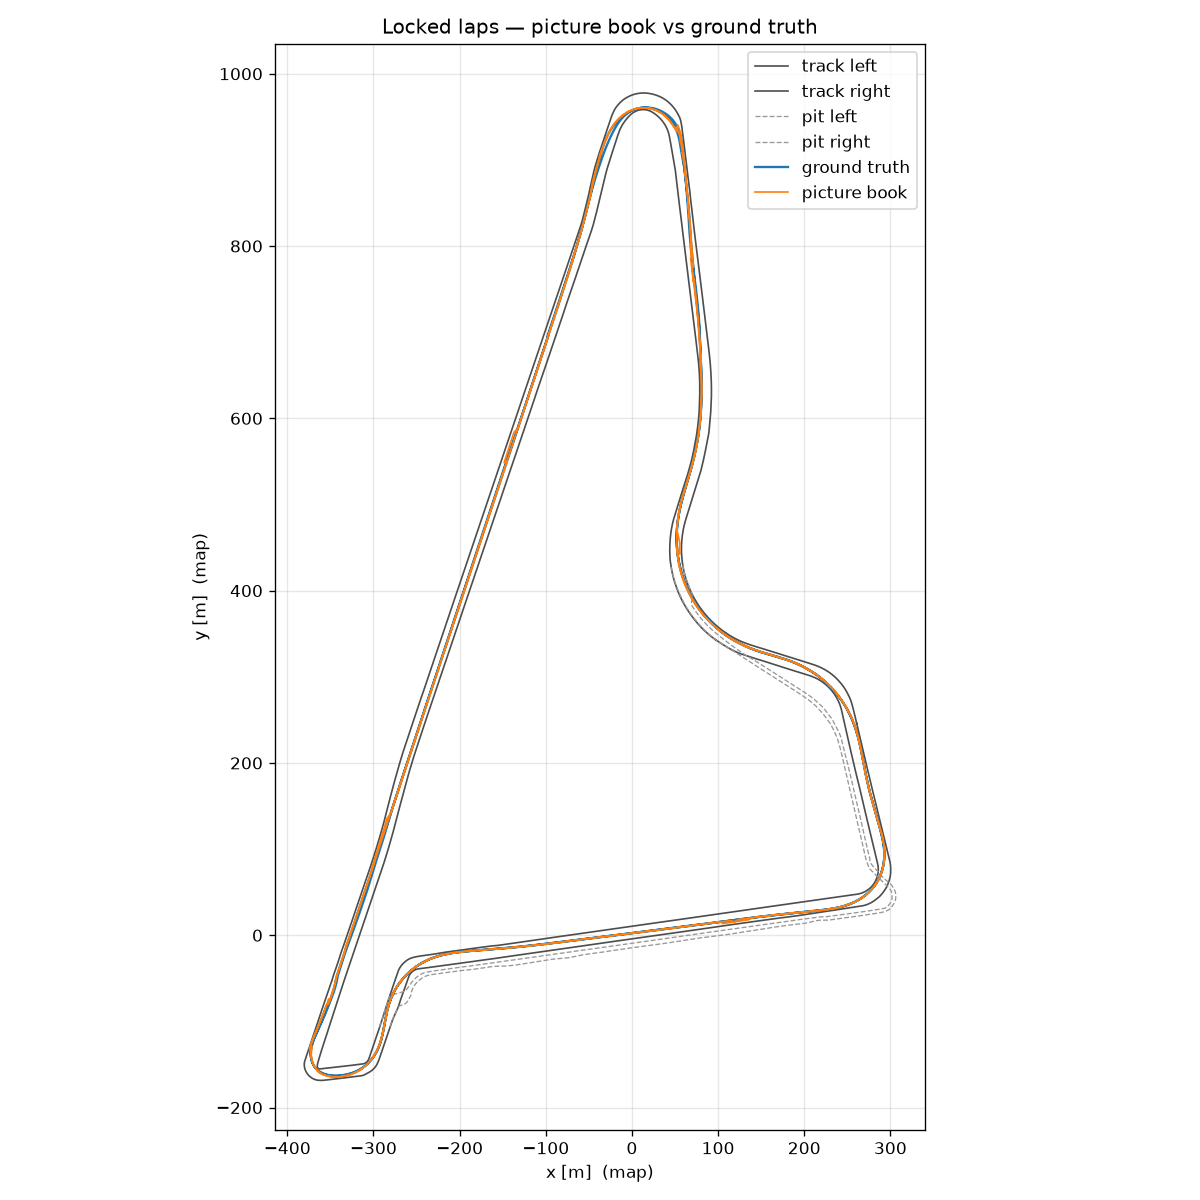

wrote output/retrieval_validation_laps.png


In [14]:
sub = np.genfromtxt(OUT_DIR / "submission_retrieval.csv", delimiter=",", names=True, dtype=None, encoding=None)
gt_mask = (gt["timestamp_ns"] >= val_t0) & (gt["timestamp_ns"] < val_t1)
sub_mask = (sub["timestamp_ns"] >= val_t0) & (sub["timestamp_ns"] < val_t1)

fig, ax = plt.subplots(figsize=(10, 10))
for name, xy in borders.items():
    ax.plot(xy[:, 0], xy[:, 1], **style.get(name, dict(label=name)))
ax.plot(gt["x"][gt_mask][::10], gt["y"][gt_mask][::10], color="C0", lw=1.4, label="ground truth")
ax.plot(sub["x"][sub_mask], sub["y"][sub_mask], color="C1", lw=1.0, label="picture book")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]  (map)")
ax.set_ylabel("y [m]  (map)")
ax.set_title("Locked laps — picture book vs ground truth")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "retrieval_validation_laps.png", dpi=120)
plt.show()
print("wrote", OUT_DIR / "retrieval_validation_laps.png")
